## Gas emissions by sector

Now, we will seek to determine two things:

- Which sectors are the most polluting for each gas;
- Which gases are the most polluting for each sector.

In [1]:
import pandas as pd

In [2]:
emissions_per_year = pd.read_csv('/emissions_per_year.csv')

In [4]:
gas_per_sector = emissions_per_year.groupby(['Gás', 'Nível 1 - Setor'])[['Emission']].sum()
gas_per_sector

Emission
Gás      Nível 1 - Setor                                 
C2F6 (t) Processos Industriais               1.791722e+01
CF4 (t)  Processos Industriais               2.740165e+02
CH4 (t)  Agropecuária                        4.833157e+07
         Energia                             6.460806e+06
         Mudança de Uso da Terra e Floresta  0.000000e+00
...                                                   ...
N2O (t)  Resíduos                            1.796227e+04
NOx (t)  Agropecuária                        1.684249e+05
         Energia                             5.586073e+06
         Processos Industriais               1.293527e+05
SF6 (t)  Processos Industriais               0.000000e+00

[72 rows x 1 columns]

To identify the sector that emits the highest amount of CO2, we can perform a specific selection for the gas CO2 using the `xs()` (cross-section) method, and subsequently extract the maximum value and its corresponding index using the `max()` and `idxmax()` methods.

In [6]:
gas_per_sector.xs('CO2 (t)', level=0)

,Emission
Nível 1 - Setor,
Agropecuária,1.360134e+07
Energia,7.700692e+08
Mudança de Uso da Terra e Floresta,0.000000e+00
Processos Industriais,1.030753e+08
Resíduos,6.822397e+05


In [8]:
gas_per_sector.xs(('CO2 (t)', 'Energia'), level=[0, 1])

,,Emission
Gás,Nível 1 - Setor,
CO2 (t),Energia,7.700692e+08


In [9]:
gas_per_sector.xs('CO2 (t)', level=0).max()

,0
Emission,7.700692e+08


In [11]:
gas_per_sector.xs('CO2 (t)', level=0).idxmax()

,0
Emission,Energia


To avoid a manual approach for each type of gas, we can further explore the `groupby()` method in conjunction with [`idxmax()`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.idxmax.html?highlight=idxmax#pandas.core.groupby.DataFrameGroupBy.idxmax).

In [19]:
gas_per_sector.groupby(level=0).idxmax()

,Emission
Gás,
C2F6 (t),"(C2F6 (t), Processos Industriais)"
CF4 (t),"(CF4 (t), Processos Industriais)"
CH4 (t),"(CH4 (t), Agropecuária)"
CO (t),"(CO (t), Energia)"
CO2 (t),"(CO2 (t), Energia)"
CO2e (t) GTP-AR2,"(CO2e (t) GTP-AR2, Energia)"
CO2e (t) GTP-AR4,"(CO2e (t) GTP-AR4, Energia)"
CO2e (t) GTP-AR5,"(CO2e (t) GTP-AR5, Energia)"
CO2e (t) GTP-AR6,"(CO2e (t) GTP-AR6, Energia)"


Finally, we can create a summary table containing information on the maximum emission values ​​for each type of gas, along with a reference to the sector with the highest emissions for each gas.

In [20]:
gas_per_sector.groupby(level=0).max()

,Emission
Gás,
C2F6 (t),1.791722e+01
CF4 (t),2.740165e+02
CH4 (t),4.833157e+07
CO (t),5.927147e+07
CO2 (t),7.700692e+08
CO2e (t) GTP-AR2,8.264984e+08
CO2e (t) GTP-AR4,8.264984e+08
CO2e (t) GTP-AR5,8.168209e+08
CO2e (t) GTP-AR6,8.236115e+08


In [21]:
max_values = gas_per_sector.groupby(level=0).max().values

In [22]:
summarized_table = gas_per_sector.groupby(level=0).idxmax()
summarized_table.insert(1, 'Emission quantity', max_values)
summarized_table

,Emission,Emission quantity
Gás,,
C2F6 (t),"(C2F6 (t), Processos Industriais)",1.791722e+01
CF4 (t),"(CF4 (t), Processos Industriais)",2.740165e+02
CH4 (t),"(CH4 (t), Agropecuária)",4.833157e+07
CO (t),"(CO (t), Energia)",5.927147e+07
CO2 (t),"(CO2 (t), Energia)",7.700692e+08
CO2e (t) GTP-AR2,"(CO2e (t) GTP-AR2, Energia)",8.264984e+08
CO2e (t) GTP-AR4,"(CO2e (t) GTP-AR4, Energia)",8.264984e+08
CO2e (t) GTP-AR5,"(CO2e (t) GTP-AR5, Energia)",8.168209e+08
CO2e (t) GTP-AR6,"(CO2e (t) GTP-AR6, Energia)",8.236115e+08


We can change the order of the index levels to uncover different information—specifically, which gas is emitted the most for each type of sector. To do this, we will use the [`swaplevel()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.swaplevel.html) method.

In [23]:
gas_per_sector.swaplevel(0, 1)

Emission
Nível 1 - Setor                    Gás                   
Processos Industriais              C2F6 (t)  1.791722e+01
                                   CF4 (t)   2.740165e+02
Agropecuária                       CH4 (t)   4.833157e+07
Energia                            CH4 (t)   6.460806e+06
Mudança de Uso da Terra e Floresta CH4 (t)   0.000000e+00
...                                                   ...
Resíduos                           N2O (t)   1.796227e+04
Agropecuária                       NOx (t)   1.684249e+05
Energia                            NOx (t)   5.586073e+06
Processos Industriais              NOx (t)   1.293527e+05
                                   SF6 (t)   0.000000e+00

[72 rows x 1 columns]

In [26]:
gas_per_sector.swaplevel(0, 1).groupby(level=0).idxmax()


,Emission
Nível 1 - Setor,
Agropecuária,"(Agropecuária, CO2e (t) GWP-AR5)"
Energia,"(Energia, CO2e (t) GWP-AR5)"
Mudança de Uso da Terra e Floresta,"(Mudança de Uso da Terra e Floresta, CH4 (t))"
Processos Industriais,"(Processos Industriais, CO2e (t) GWP-AR2)"
Resíduos,"(Resíduos , CO2e (t) GWP-AR5)"


### Emissions over the years

We will determine whether greenhouse gas emissions have increased or decreased over the years and visualize this variation separately for each type of gas emitted.

In [32]:
emissions_per_year

,Nível 1 - Setor,Nível 2,Nível 3,Nível 4,Nível 5,Nível 6,Gás,Estado,Atividade Econômica,Produto,Year,Emission
0,Processos Industriais,Indústria Química,Produção de ABS,NaN,NaN,NaN,COVNM (t),SP,OUTRA_IND,NaN,1970.0,0.0
1,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,N2O (t),SP,OUTRA_IND,NaN,1970.0,6210.0
2,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,CO (t),SP,OUTRA_IND,NaN,1970.0,368.0
3,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,NOx (t),SP,OUTRA_IND,NaN,1970.0,115.0
4,Processos Industriais,Indústria Química,Produção de Ácido Adípico,NaN,NaN,NaN,CO2e (t) GWP-AR2,SP,OUTRA_IND,NaN,1970.0,1925100.0
...,...,...,...,...,...,...,...,...,...,...,...,...
718877,Mudança de Uso da Terra e Floresta,Remoção por Mudança de Uso da Terra,Mata Atlântica,em Área Protegida,Outras Mudanças de uso da terra,Área sem vegetação -- Silvicultura,CO2 (t),RS,AGROPEC,NaN,1976.0,0.0
718878,Mudança de Uso da Terra e Floresta,Remoção por Mudança de Uso da Terra,Mata Atlântica,em Área Protegida,Outras Mudanças de uso da terra,Área sem vegetação -- Silvicultura,CO2 (t),SC,AGROPEC,NaN,1976.0,0.0
718879,Mudança de Uso da Terra e Floresta,Remoção por Mudança de Uso da Terra,Mata Atlântica,em Área Protegida,Outras Mudanças de uso da terra,Área sem vegetação -- Silvicultura,CO2 (t),SP,AGROPEC,NaN,1976.0,0.0
718880,Mudança de Uso da Terra e Floresta,Remoção por Mudança de Uso da Terra,Mata Atlântica,em Área Protegida,Outras Mudanças de uso da terra,Área sem vegetação -- Silvicultura,CO2e (t) GTP-AR2,MG,AGROPEC,NaN,1976.0,0.0


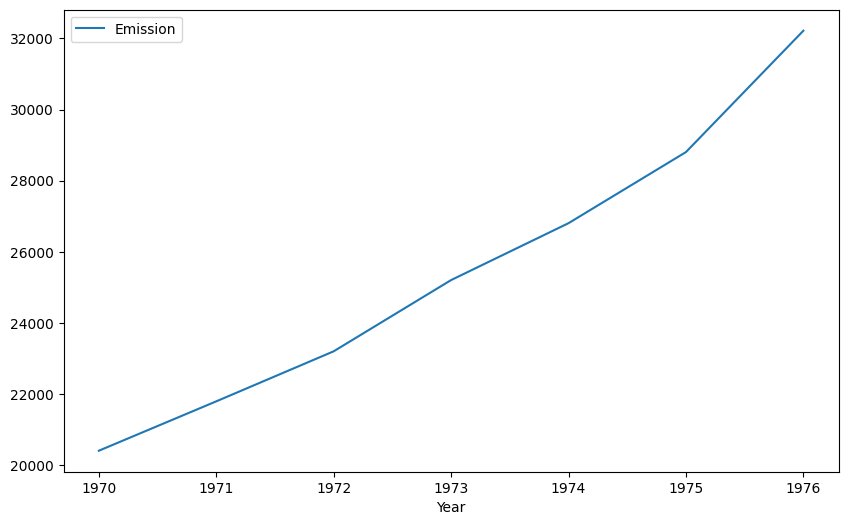

In [29]:
emissions_per_year.groupby('Year')[['Emission']].mean().plot(figsize=(10,6));

In [30]:
emissions_per_year.groupby('Year')[['Emission']].mean().idxmax()

,0
Emission,1976.0


In [31]:
emissions_per_year.groupby(['Year', 'Gás'])[['Emission']].mean()

Emission
Year   Gás                     
1970.0 C2F6 (t)        0.232610
       CF4 (t)         3.557421
       CH4 (t)      1468.366197
       CO (t)       2154.429254
       CO2 (t)     16208.866464
...                         ...
1976.0 HFC-23 (t)      0.000000
       HFC-32 (t)      0.000000
       N2O (t)        41.908985
       NOx (t)       286.788433
       SF6 (t)         0.000000

[161 rows x 1 columns]

In [33]:
average_emission_annual = emissions_per_year.groupby(['Year', 'Gás'])[['Emission']].mean().reset_index()
average_emission_annual

,Year,Gás,Emission
0,1970.0,C2F6 (t),0.232610
1,1970.0,CF4 (t),3.557421
2,1970.0,CH4 (t),1468.366197
3,1970.0,CO (t),2154.429254
4,1970.0,CO2 (t),16208.866464
...,...,...,...
156,1976.0,HFC-23 (t),0.000000
157,1976.0,HFC-32 (t),0.000000
158,1976.0,N2O (t),41.908985
159,1976.0,NOx (t),286.788433


In [34]:
average_emission_annual = average_emission_annual.pivot_table(index='Year', columns='Gás', values='Emission')
average_emission_annual

Gás,C2F6 (t),CF4 (t),CH4 (t),CO (t),CO2 (t),CO2e (t) GTP-AR2,CO2e (t) GTP-AR4,CO2e (t) GTP-AR5,CO2e (t) GTP-AR6,CO2e (t) GWP-AR2,...,COVNM (t),HFC-125 (t),HFC-134a (t),HFC-143a (t),HFC-152a (t),HFC-23 (t),HFC-32 (t),N2O (t),NOx (t),SF6 (t)
Year,,,,,,,,,,,,,,,,,,,,,
1970.0,0.232610,3.557421,1468.366197,2154.429254,16208.866464,18862.703799,18862.703799,17370.674172,17921.680291,31972.459540,...,741.692873,0.0,0.0,0.0,0.0,0.0,0.0,31.590338,159.944249,0.0
1971.0,0.334611,5.117360,1522.749052,2258.483712,18146.100667,20331.726520,20331.726520,18786.502412,19360.117065,33918.077574,...,729.773925,0.0,0.0,0.0,0.0,0.0,0.0,32.564894,177.219333,0.0
1972.0,0.404684,6.189025,1581.855297,2417.704589,19877.907343,21811.052503,21811.052503,20194.514777,20791.408670,35933.295351,...,773.908363,0.0,0.0,0.0,0.0,0.0,0.0,34.265347,195.786087,0.0
1973.0,0.463147,7.083136,1639.621403,2594.007500,23040.103307,24008.339911,24008.339911,22338.262259,22958.289918,38637.085426,...,796.232223,0.0,0.0,0.0,0.0,0.0,0.0,35.225461,217.153952,0.0
1974.0,0.471026,7.203619,1701.513896,2679.348234,25101.967674,25703.767093,25703.767093,23959.827151,24608.023330,40897.425131,...,1023.881477,0.0,0.0,0.0,0.0,0.0,0.0,37.043361,247.348600,0.0
1975.0,0.502952,7.691893,1850.983878,2728.741345,26829.916884,27523.595441,27523.595441,25647.230246,26346.986093,44029.537867,...,1064.834308,0.0,0.0,0.0,0.0,0.0,0.0,39.391377,262.512975,0.0
1976.0,0.577172,8.826970,1950.837220,2700.361944,31998.326806,31310.605039,31314.104603,29242.835146,30013.378157,49434.314468,...,1090.909415,0.0,0.0,0.0,0.0,0.0,0.0,41.908985,286.788433,0.0


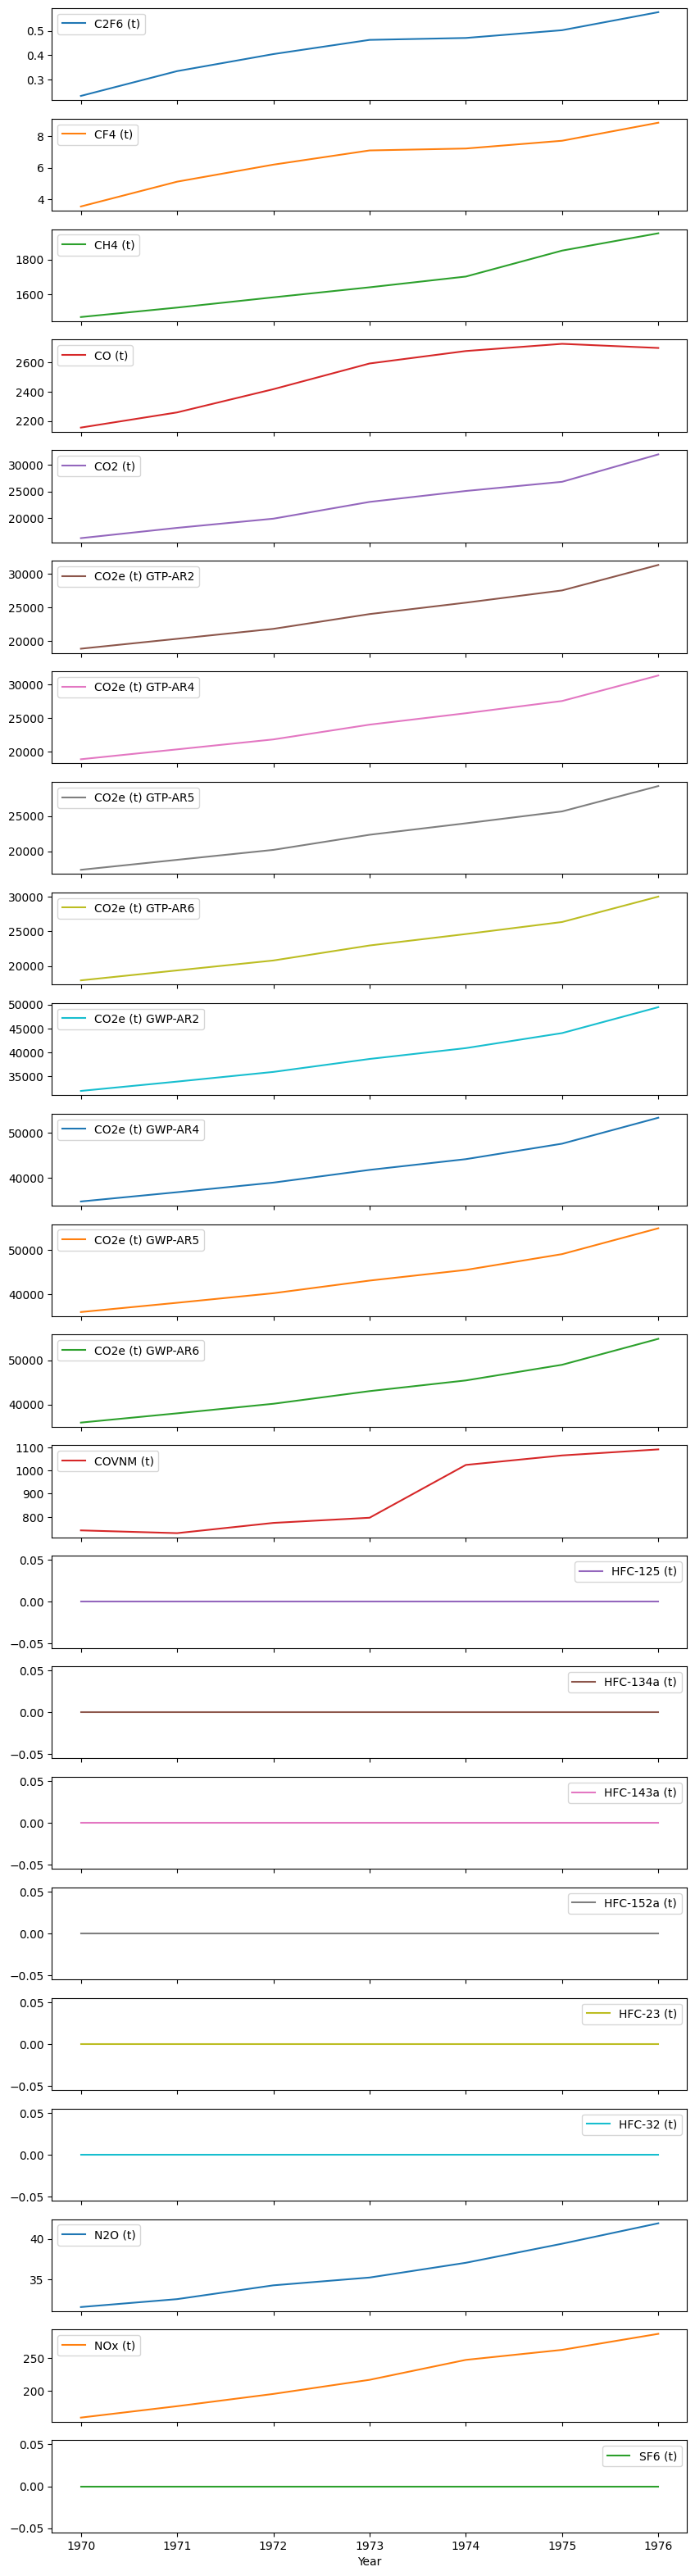

In [36]:
average_emission_annual.plot(subplots=True, figsize=(10, 40));